# Busca em profundidade (DFS)
## Implementação em C e análise experimental com Python
**SSC0503 — Sistemas de Informação — ICMC-USP**

Nome: Paulo Nunes de Azevedo Número USP: 13839010

**Atividade individual.

Você implementará em **C11, não C++**, as estruturas e os percursos da busca em profundidade. Python cuidará da compilação, leitura de arquivos, validação e visualização. A implementação dos algoritmos é trabalho seu; os programas de apoio chamarão essas funções, sem substituí-las.

Aplicação: auditar uma rede de computadores sem pesos, identificar componentes isoladas e ciclos e recuperar um caminho na árvore de busca. A DFS não garante uma rota com o menor número de enlaces. A análise envolve conectividade, sem inferir latência ou confiabilidade física da rede.

Entregue este `.ipynb` com código C, testes, saídas e respostas. Reinicie a sessão e execute as células em ordem antes de fazer o download. Os arquivos `.c`, `.h` e `.csv` do ambiente são temporários, mas serão recriados pelas células do notebook.


## 1. O que praticar a partir dos slides

Os slides apresentam a DFS por ramos, o retorno ao antecessor, três estados, predecessores, tempos de descoberta e término e uma floresta para cobrir todas as componentes. A sequência final distingue a recursão, a pilha de quadros e a variante que empilha somente vértices. Nesta atividade, a equivalência exigida é entre **recursão e pilha de quadros**, incluindo os términos.

Usaremos o grafo da sequência detalhada dos slides, cujos vizinhos de A são B e C e os de D são B e E. Os primeiros slides ilustram também outro grafo: não misture suas arestas com as do caso de teste detalhado. As referências a páginas usam a posição no PDF, pois os contadores antigos dos slides não formam uma numeração única.

Objetivos:

- reutilizar a lista ligada de adjacências da atividade de BFS e preservar sua ordem;
- implementar pilha LIFO com alocação dinâmica;
- implementar DFS recursiva e iterativa com continuação salva;
- registrar `estado`, `pai`, `d`, `f`, componente e ordens de descoberta/término;
- identificar ciclos em grafos simples não dirigidos, sem confundir a aresta para o pai;
- reconstruir um caminho pelo vetor de pais;
- comparar contagens e tempo usando lista e matriz.

| Critério | Peso |
|---|---:|
| Grafo, pilha e memória dinâmica | 20% |
| DFS recursiva e floresta completa | 20% |
| DFS iterativa e equivalência com a recursiva | 25% |
| DFS com matriz e contagem de operações | 10% |
| Caminhos, componentes e ciclo | 10% |
| Testes próprios e interpretação experimental | 15% |

Não use implementações prontas de grafos ou de DFS. Você pode reutilizar **seu próprio** código C do grafo da atividade de BFS, adaptando-o aos contratos. Os cabeçalhos, programas de apoio e testes estão prontos. Complete as células marcadas com `TODO`; mantenha o cálculo dos percursos em C.


## 2. Executando C no Colab

Uma célula iniciada por `%%writefile nome.c` grava as linhas seguintes no arquivo indicado. Depois de editar uma implementação, **execute a célula novamente** para atualizar o arquivo antes de compilar.

A compilação fornecida usa `gcc -std=c11 -Wall -Wextra -Wpedantic -O2`. Os erros e avisos serão apresentados pelo Python. Primeiro preencha todas as implementações, depois execute `compilar()` e os testes. Você também pode verificar isoladamente um arquivo com `!gcc -std=c11 -Wall -Wextra -Wpedantic -c nome.c`.

Os programas C exportam CSV. Python não executa a DFS por você. A referência de componentes usada nos testes é uma união de conjuntos independente, exclusiva da validação.


In [1]:
from pathlib import Path
import subprocess
import shutil
import math
import random
import statistics
import pandas as pd
import matplotlib.pyplot as plt

FONTES = ['grafo_lista.c','pilha.c','apoio.c','dfs_rec.c','dfs_iter.c','dfs_matriz.c','caminho.c']
PRONTO = False

def compilar():
    global PRONTO
    PRONTO = False
    faltam = [p for p in FONTES if not Path(p).exists() or 'TODO' in Path(p).read_text()]
    if faltam:
        print('Complete primeiro:', ', '.join(faltam)); return False
    if not shutil.which('gcc'): raise RuntimeError('Compilador gcc não encontrado neste ambiente.')
    for alvo, principal in [('executa_dfs','executa_dfs.c'),('teste_estruturas','teste_estruturas.c')]:
        comando=['gcc','-std=c11','-Wall','-Wextra','-Wpedantic','-O2',*FONTES,principal,'-o',alvo]
        p=subprocess.run(comando,capture_output=True,text=True)
        if p.stdout: print(p.stdout)
        if p.stderr: print(p.stderr)
        if p.returncode: raise RuntimeError(f'Compilação de {alvo} falhou. Corrija as mensagens acima.')
    PRONTO = True
    print('Dois executáveis C11 compilados. Todas as implementações serão chamadas pelos testes.')
    return True

def gravar_grafo(nome,n,arestas,primeira=-1):
    p=Path(nome)
    p.write_text(f'{n} {len(arestas)} {primeira}\n'+''.join(f'{u} {v}\n' for u,v in arestas))
    return p

def rodar(entrada,modo,prefixo,repeticoes=1):
    if not PRONTO: raise RuntimeError('Preencha as implementações e execute compilar() primeiro.')
    try:
        p=subprocess.run(['./executa_dfs',str(entrada),modo,str(prefixo),str(repeticoes)],
                         capture_output=True,text=True,timeout=15)
    except subprocess.TimeoutExpired as e:
        raise RuntimeError('Execução excedeu 15 s. Verifique se o quadro avança e se o laço termina.') from e
    if p.returncode:
        raise RuntimeError(f'C retornou código {p.returncode}. {p.stderr.strip()}')
    tabela=pd.read_csv(f'{prefixo}.vertices.csv')
    metricas=pd.read_csv(f'{prefixo}.metricas.csv').iloc[0].to_dict()
    caminhos=pd.read_csv(f'{prefixo}.caminhos.csv',keep_default_na=False,dtype={'caminho':str})
    return tabela,metricas,caminhos

ARESTAS_AULA = [(0,1),(0,2),(1,3),(1,4),(2,5),(2,6),(3,4),(5,7)]
ARESTAS_BFS = [(0,1),(0,2),(1,3),(1,4),(2,4),(2,5),(3,6),(4,6),(4,7),(5,7)]
print('Apoio Python carregado. Os algoritmos de percurso serão executados em C.')


Apoio Python carregado. Os algoritmos de percurso serão executados em C.


## 3. Exercício 1 — Grafo com listas ligadas

O cabeçalho abaixo é compatível com a representação usada na atividade de BFS. Cada aresta não dirigida u–v insere dois nós, um em cada lista. A inserção ocorre **no final**, preservando a ordem de entrada.

Implemente ou adapte `grafo_lista.c`:

- `grafo_lista_cria(n)` devolve um grafo válido para n ≥ 0; para n = 0, as listas podem ser `NULL`. Retorna `NULL` em tamanho negativo ou falha de alocação.
- `grafo_lista_adiciona_aresta` devolve 1 se inseriu e 0 em falha, vértice inválido, laço ou aresta repetida. Se a segunda alocação falhar, não deixe apenas metade da aresta inserida.
- `grafo_lista_imprime` mostra os vizinhos, sem mudar a estrutura.
- `grafo_lista_libera` libera todos os nós, vetores e o grafo; aceita `NULL`.

Os testes usam grafos **simples e não dirigidos**. Essa hipótese é necessária para a regra de ciclo adotada aqui. Não crie ordenação automática das listas: os percursos com lista devem respeitar sua ordem de inserção.


In [2]:
%%writefile grafo_lista.h
#ifndef GRAFO_LISTA_H
#define GRAFO_LISTA_H

typedef struct NoAdj { int vertice; struct NoAdj *prox; } NoAdj;
typedef struct { int n; NoAdj **inicio; NoAdj **fim; } GrafoLista;
GrafoLista *grafo_lista_cria(int n);
int grafo_lista_adiciona_aresta(GrafoLista *g, int u, int v);
void grafo_lista_imprime(const GrafoLista *g);
void grafo_lista_libera(GrafoLista *g);
#endif


Overwriting grafo_lista.h


In [3]:
%%writefile grafo_lista.c
#include "grafo_lista.h"
#include <stdio.h>
#include <stdlib.h>

static int adiciona_direcionada(GrafoLista *g, int u, int v)
{
    NoAdj *no = malloc(sizeof(NoAdj));
    if (no == NULL)
        return 0;

    no->vertice = v;
    no->prox = NULL;

    if (g->inicio[u] == NULL)
        g->inicio[u] = no;
    else
        g->fim[u]->prox = no;
    g->fim[u] = no;
    return 1;
}

GrafoLista *grafo_lista_cria(int n)
{
    if (n < 0)
        return NULL;

    GrafoLista *g = malloc(sizeof(GrafoLista));
    if (g == NULL)
        return NULL;

    g->n = n;
    g->inicio = NULL;
    g->fim = NULL;
    if (n == 0)
        return g;

    g->inicio = calloc(n, sizeof(NoAdj *));
    g->fim = calloc(n, sizeof(NoAdj *));
    if (g->inicio == NULL || g->fim == NULL)
    {
        free(g->inicio);
        free(g->fim);
        free(g);
        return NULL;
    }
    return g;
}

int grafo_lista_adiciona_aresta(GrafoLista *g, int u, int v)
{
    if (g == NULL || u < 0 || u >= g->n || v < 0 || v >= g->n || u == v)
        return 0;

    for (NoAdj *p = g->inicio[u]; p != NULL; p = p->prox)
        if (p->vertice == v)
            return 0;

    NoAdj *fim_anterior = g->fim[u];
    if (!adiciona_direcionada(g, u, v))
        return 0;

    if (!adiciona_direcionada(g, v, u))
    {
        free(g->fim[u]);
        g->fim[u] = fim_anterior;
        if (fim_anterior == NULL)
            g->inicio[u] = NULL;
        else
            fim_anterior->prox = NULL;
        return 0;
    }
    return 1;
}

void grafo_lista_imprime(const GrafoLista *g)
{
    if (g == NULL)
        return;

    for (int u = 0; u < g->n; u++)
    {
        printf("%d:", u);
        for (NoAdj *p = g->inicio[u]; p != NULL; p = p->prox)
            printf(" %d", p->vertice);
        printf("\n");
    }
}

void grafo_lista_libera(GrafoLista *g)
{
    if (g == NULL)
        return;

    for (int u = 0; u < g->n; u++)
    {
        NoAdj *p = g->inicio[u];
        while (p != NULL)
        {
            NoAdj *prox = p->prox;
            free(p);
            p = prox;
        }
    }
    free(g->inicio);
    free(g->fim);
    free(g);
}


Overwriting grafo_lista.c


**1.1 — Ordem e representação**

Cada aresta u–v entra nas duas listas (v na lista de u e u na lista de v), porque a rede não tem direção. A inserção é sempre no **final** e o ponteiro `fim` permite isso sem percorrer a lista. Assim os vizinhos ficam na mesma ordem em que as arestas foram lidas.

Essa ordem importa: a DFS visita os vizinhos na ordem da lista, então ela decide quem vira pai de quem e quais são os tempos `d`/`f`. Por isso a lista não é ordenada automaticamente. A lista também ocupa só o necessário: um nó por "ponta" de aresta, ou seja, 2E nós mais os vetores `inicio` e `fim`.


## 4. Exercício 2 — Pilha LIFO de quadros

Um quadro precisa guardar o vértice atual **e onde continuar sua lista de vizinhos**.

Nos slides, essa continuação é um índice i. Em uma **lista ligada**, obter o i-ésimo vizinho recomeçando do início a cada vez pode gerar custo quadrático no grau do vértice. Por isso usaremos `const NoAdj *proximo`, que aponta diretamente para o próximo nó ainda não examinado. O ponteiro é `NULL` quando a lista terminou.

Implemente `pilha.c` usando um vetor de `Quadro` alocado dinamicamente:

| Função | Contrato |
|---|---|
| `pilha_cria(capacidade)` | Capacidade positiva; retornar `NULL` se inválida ou se malloc falhar |
| `pilha_vazia`, `pilha_cheia` | Informar se a quantidade é zero ou igual à capacidade |
| `pilha_empilha(p,q)` | Copiar q para o topo; 1 em sucesso, 0 se cheia ou inválida |
| `pilha_topo(p)` | Ponteiro para o quadro **armazenado**, ou `NULL` se vazia |
| `pilha_desempilha(p,saida)` | 1 em sucesso, 0 se vazia; se saida não é NULL, copiar o quadro retirado |
| `pilha_libera` | Liberar vetor e estrutura; aceitar NULL |

A pilha não é proprietária dos nós de adjacência: não os libere ao retirar um quadro. Eles pertencem ao grafo. A capacidade n é suficiente na DFS com quadros, porque cada vértice é descoberto e empilhado uma única vez.

```text
EMPILHAR(q): se cheia, falhar; dados[quantidade] ← q; quantidade++
TOPO: se vazia, devolver NULL; devolver endereço de dados[quantidade−1]
DESEMPILHAR: se vazia, falhar; quantidade--; copiar quadro, se solicitado
```


In [4]:
%%writefile pilha.h
#ifndef PILHA_H
#define PILHA_H
#include "grafo_lista.h"
typedef struct { int vertice; const NoAdj *proximo; } Quadro;
typedef struct { Quadro *dados; int capacidade; int quantidade; } Pilha;
Pilha *pilha_cria(int capacidade);
int pilha_vazia(const Pilha *p);
int pilha_cheia(const Pilha *p);
int pilha_empilha(Pilha *p, Quadro q);
Quadro *pilha_topo(Pilha *p);
int pilha_desempilha(Pilha *p, Quadro *saida);
void pilha_libera(Pilha *p);
#endif


Overwriting pilha.h


In [5]:
%%writefile pilha.c
#include "pilha.h"
#include <stdlib.h>

Pilha *pilha_cria(int capacidade)
{
    if (capacidade <= 0)
        return NULL;

    Pilha *p = malloc(sizeof(Pilha));
    if (p == NULL)
        return NULL;

    p->dados = malloc(capacidade * sizeof(Quadro));
    if (p->dados == NULL)
    {
        free(p);
        return NULL;
    }

    p->capacidade = capacidade;
    p->quantidade = 0;
    return p;
}

int pilha_vazia(const Pilha *p)
{
    if (p == NULL || p->quantidade == 0)
        return 1;
    else
        return 0;
}

int pilha_cheia(const Pilha *p)
{
    if (p != NULL && p->quantidade == p->capacidade)
        return 1;
    else
        return 0;
}

int pilha_empilha(Pilha *p, Quadro q)
{
    if (p == NULL || pilha_cheia(p))
        return 0;

    p->dados[p->quantidade] = q;
    p->quantidade++;
    return 1;
}

Quadro *pilha_topo(Pilha *p)
{
    if (pilha_vazia(p))
        return NULL;

    return &p->dados[p->quantidade - 1];
}

int pilha_desempilha(Pilha *p, Quadro *saida)
{
    if (pilha_vazia(p))
        return 0;

    p->quantidade--;
    if (saida != NULL)
        *saida = p->dados[p->quantidade];
    return 1;
}

void pilha_libera(Pilha *p)
{
    if (p == NULL)
        return;
    free(p->dados);
    free(p);
}


Overwriting pilha.c


**2.1 — Ponteiro para o topo**

`pilha_topo` devolve o endereço do quadro que está **dentro** da pilha, não uma cópia. Quando a DFS faz `q->proximo = atual->prox`, ela altera o próprio quadro guardado e o avanço fica salvo para a próxima vez que esse vértice voltar ao topo.

Se fosse uma cópia, o avanço se perderia e o mesmo vizinho seria examinado de novo para sempre. Um cuidado: o ponteiro só vale até o próximo empilhamento/desempilhamento. Por isso avanço `proximo` **antes** de empilhar o filho e não uso `q` depois disso.


## 5. Contrato comum dos resultados e apoio fornecido

Leia o cabeçalho e execute as células prontas. `resultado_cria` aloca os vetores e `resultado_reinicia` inicializa estados, pais e contadores. Você deve chamar `resultado_reinicia(r)` no início de cada percurso válido, para permitir executar outra vez com o mesmo objeto. Não realoque os vetores dentro da DFS.

| Campo | Significado |
|---|---|
| `estado[v]` | 0 não descoberto, 1 em processamento, 2 finalizado |
| `pai[v]` | Antecessor na árvore, ou −1 para uma raiz |
| `d[v]`, `f[v]` | Tempos de descoberta e término, iniciados em 1 |
| `componente[v]` | Identificador de componente iniciado em 0 |
| `ordem_d`, `ordem_f` | Sequências de descoberta e término; `tam_d`, `tam_f` são seus tamanhos |
| `tempo` | Relógio global da execução, sem reiniciar entre componentes |
| `componentes`, `tem_ciclo` | Total de componentes e indicador 0/1 de ciclo |
| `exames` | Entradas das listas ou células da matriz examinadas |
| `max_pilha` | Máximo de chamadas recursivas ou quadros simultaneamente ativos |

As três DFS percorrem **todo o grafo**. Com `primeira=-1`, tente raízes 0,1,…,n−1. Com uma primeira raiz válida, percorra sua componente antes das demais raízes em ordem crescente. Raízes já descobertas são ignoradas. Para n=0, use primeira=-1 e devolva resultado vazio. Valores menores que −1 ou maiores/iguais a n são inválidos.

As funções DFS retornam 1 em sucesso e 0 em erro de parâmetro/alocação. Ao final de uma floresta completa: todos os estados são 2; `tam_d=tam_f=n`; `tempo=2*n`; os tempos são distintos.

`registra_evento` é apoio de exportação: não decide onde o algoritmo vai. Seu uso será obrigatório somente na DFS iterativa e apenas quando `rastro != NULL`.


In [6]:
%%writefile dfs.h
#ifndef DFS_H
#define DFS_H
#include <stdio.h>
#include "grafo_lista.h"
#include "pilha.h"
enum { NAO_DESCOBERTO = 0, EM_PROCESSAMENTO = 1, FINALIZADO = 2 };
typedef struct {
    int n;
    int *estado, *pai, *d, *f, *componente, *ordem_d, *ordem_f;
    int tempo, tam_d, tam_f, componentes, tem_ciclo, max_pilha;
    long long exames;
} ResultadoDFS;
/* Apoio fornecido. */
int resultado_cria(ResultadoDFS *r, int n);
void resultado_reinicia(ResultadoDFS *r);
void resultado_libera(ResultadoDFS *r);
void registra_evento(FILE *arq, const GrafoLista *g, const ResultadoDFS *r,
                     const Pilha *p, const char *evento, int vertice);
/* Funcoes a implementar. primeira=-1 usa todas as raizes em ordem crescente. */
int dfs_recursiva(const GrafoLista *g, int primeira, ResultadoDFS *r);
int dfs_iterativa(const GrafoLista *g, int primeira, ResultadoDFS *r, FILE *rastro);
int dfs_matriz(const unsigned char *matriz, int n, int primeira, ResultadoDFS *r);
int reconstroi_caminho(const int pai[], int n, int origem, int destino,
                      int caminho[], int capacidade);
#endif


Overwriting dfs.h


In [7]:
%%writefile apoio.c
#include <stdlib.h>
#include <string.h>
#include "dfs.h"
int resultado_cria(ResultadoDFS *r,int n) {
    if (!r || n<0) return 0;
    memset(r,0,sizeof(*r)); r->n=n;
    size_t tam=(size_t)(n>0?n:1);
    r->estado=malloc(tam*sizeof(int)); r->pai=malloc(tam*sizeof(int));
    r->d=malloc(tam*sizeof(int));r->f=malloc(tam*sizeof(int));
    r->componente=malloc(tam*sizeof(int));r->ordem_d=malloc(tam*sizeof(int));
    r->ordem_f=malloc(tam*sizeof(int));
    if (!r->estado||!r->pai||!r->d||!r->f||!r->componente||!r->ordem_d||!r->ordem_f) {
        resultado_libera(r);return 0;
    }
    resultado_reinicia(r); return 1;
}
void resultado_reinicia(ResultadoDFS *r) {
    r->tempo=r->tam_d=r->tam_f=r->componentes=r->tem_ciclo=r->max_pilha=0;
    r->exames=0;
    for(int i=0;i<r->n;++i){r->estado[i]=NAO_DESCOBERTO;r->pai[i]=-1;
        r->d[i]=r->f[i]=0;r->componente[i]=r->ordem_d[i]=r->ordem_f[i]=-1;}
}
void resultado_libera(ResultadoDFS *r) {
    if(!r)return;
    free(r->estado);free(r->pai);free(r->d);free(r->f);free(r->componente);
    free(r->ordem_d);free(r->ordem_f);memset(r,0,sizeof(*r));
}
void registra_evento(FILE *a,const GrafoLista *g,const ResultadoDFS *r,
                     const Pilha *p,const char *evento,int u) {
    if(!a)return;
    fprintf(a,"%d,%s,%d,%d,\"",r->tempo-1,evento,u,r->tempo);
    for(int k=0;k<p->quantidade;++k){
        Quadro q=p->dados[k];int indice=0;
        for(const NoAdj *x=g->inicio[q.vertice];x && x!=q.proximo;x=x->prox)++indice;
        if(k)fputc(';',a);
        fprintf(a,"%d:%d",q.vertice,indice);
    }
    fprintf(a,"\",\"");
    for(int v=0;v<g->n;++v){if(v)fputc(';',a);fprintf(a,"%d",r->estado[v]);}
    fprintf(a,"\"\n");
}


Overwriting apoio.c


## 6. Exercício 3 — DFS recursiva e floresta

Complete `dfs_rec.c`, criando uma função auxiliar realmente recursiva. Passe a componente e a profundidade da chamada à auxiliar. A profundidade da raiz é 1.

```text
DFS_RECURSIVA(g, primeira, r):
    validar parâmetros; reiniciar resultado
    se primeira foi informada: iniciar visita nessa raiz
    para u de 0 a n−1:
        se u não descoberto: iniciar visita nessa raiz
    devolver sucesso

INICIAR_RAIZ(u):
    comp ← número atual de componentes; incrementar esse número
    VISITAR(u, comp, 1)

VISITAR(u, comp, profundidade):
    estado[u] ← em_processamento
    d[u] ← ++relógio; acrescentar u à ordem de descoberta
    componente[u] ← comp; atualizar profundidade máxima
    para cada nó p da lista de u:
        contar uma entrada examinada; v ← p.vertice
        se v não descoberto:
            pai[v] ← u; VISITAR(v, comp, profundidade+1)
        senão, se v está em processamento e v ≠ pai[u]:
            marcar existência de ciclo
    estado[u] ← finalizado
    f[u] ← ++relógio; acrescentar u à ordem de término
```

Uma aresta de volta ao pai é a própria aresta de descoberta vista na direção contrária e não deve gerar falso positivo de ciclo. Você só precisa indicar se existe ciclo; não é necessário enumerar ou reconstruir os ciclos.


In [8]:
%%writefile dfs_rec.c
#include "dfs.h"

static void visita(const GrafoLista *g, int u, int comp, int prof,
                   ResultadoDFS *r)
{
    r->estado[u] = EM_PROCESSAMENTO;
    r->d[u] = ++r->tempo;
    r->ordem_d[r->tam_d++] = u;
    r->componente[u] = comp;
    if (prof > r->max_pilha)
        r->max_pilha = prof;

    for (const NoAdj *p = g->inicio[u]; p != NULL; p = p->prox)
    {
        r->exames++;
        int v = p->vertice;
        if (r->estado[v] == NAO_DESCOBERTO)
        {
            r->pai[v] = u;
            visita(g, v, comp, prof + 1, r);
        }
        else if (r->estado[v] == EM_PROCESSAMENTO && v != r->pai[u])
            r->tem_ciclo = 1;
    }

    r->estado[u] = FINALIZADO;
    r->f[u] = ++r->tempo;
    r->ordem_f[r->tam_f++] = u;
}

int dfs_recursiva(const GrafoLista *g, int primeira, ResultadoDFS *r)
{
    if (g == NULL || r == NULL || r->n != g->n || primeira < -1 ||
        primeira >= g->n)
        return 0;

    resultado_reinicia(r);

    if (primeira != -1)
        visita(g, primeira, r->componentes++, 1, r);

    for (int u = 0; u < g->n; u++)
        if (r->estado[u] == NAO_DESCOBERTO)
            visita(g, u, r->componentes++, 1, r);

    return 1;
}


Overwriting dfs_rec.c


**3.1 — Descobrir, terminar e contar componentes**

- **Descobrir** é chegar ao vértice pela primeira vez: ele fica "em processamento" e recebe `d`.
- **Terminar** é ter examinado todos os vizinhos dele: ele fica "finalizado" e recebe `f`.

Cada vértice é descoberto uma vez e terminado uma vez, então o relógio termina em 2n. Um filho é descoberto depois do pai e termina antes dele, ou seja, o intervalo `[d, f]` do filho fica dentro do intervalo do pai (no exemplo da aula, A vai de 1 a 16 e engloba todos os outros).

Para contar componentes, o laço externo passa por todos os vértices. Toda vez que encontra um vértice ainda não descoberto, começa uma nova árvore. Cada árvore é uma componente, então o número de raízes é o número de componentes.


## 7. Exercício 4 — DFS iterativa com continuação explícita

Complete `dfs_iter.c` usando a pilha do Exercício 2. O algoritmo deve reproduzir **exatamente** os pais, tempos, componentes e ordens da versão recursiva quando usar as mesmas listas e a mesma primeira raiz.

```text
validar parâmetros; reiniciar resultado
se grafo vazio: devolver sucesso
criar pilha de capacidade n
para cada candidata a raiz, com a prioridade especificada:
    se já descoberta: continuar
    criar identificador de componente
    descobrir raiz; empilhar (raiz, inicio[raiz]); atualizar máximo
    registrar evento de descoberta
    enquanto pilha não vazia:
        q ← ponteiro para o topo; u ← q.vertice
        se q.proximo é NULL:
            finalizar u; retirar quadro
            registrar evento de finalização
        senão:
            atual ← q.proximo; v ← atual.vertice
            q.proximo ← atual.prox
            contar uma entrada examinada
            se v não descoberto:
                pai[v] ← u
                descobrir v; empilhar (v, inicio[v]); atualizar máximo
                registrar evento de descoberta
            senão, se v está em processamento e v ≠ pai[u]:
                marcar existência de ciclo
liberar pilha; devolver sucesso
```

**Descobrir** significa mudar o estado, atribuir `d`, componente e posição na ordem de descoberta. **Finalizar** significa mudar o estado, atribuir `f` e posição na ordem de término. Essas operações são responsabilidade da sua implementação.

Depois de cada descoberta/empilhamento e de cada finalização/desempilhamento, chame `registra_evento(rastro,g,r,p,"descobrir",u)` ou `"finalizar"`, usando o vértice do evento. A função pronta ignora arquivo NULL. O evento de finalização mostra a pilha **após** a retirada.

O avanço de `q->proximo` precisa ocorrer **antes de empilhar o filho**. Não substitua o algoritmo pela variante que empilha apenas vértices em ordem inversa: ela não guarda os términos e as continuações exigidos.


In [9]:
%%writefile dfs_iter.c
#include "dfs.h"

int dfs_iterativa(const GrafoLista *g, int primeira, ResultadoDFS *r,
                  FILE *rastro)
{
    if (g == NULL || r == NULL || r->n != g->n || primeira < -1 ||
        primeira >= g->n)
        return 0;

    resultado_reinicia(r);
    if (g->n == 0)
        return 1;

    Pilha *p = pilha_cria(g->n);
    if (p == NULL)
        return 0;

    for (int k = -1; k < g->n; k++)
    {
        int raiz = (k == -1) ? primeira : k;
        if (raiz == -1 || r->estado[raiz] != NAO_DESCOBERTO)
            continue;

        int comp = r->componentes++;
        r->estado[raiz] = EM_PROCESSAMENTO;
        r->d[raiz] = ++r->tempo;
        r->ordem_d[r->tam_d++] = raiz;
        r->componente[raiz] = comp;
        Quadro inicial = {raiz, g->inicio[raiz]};
        pilha_empilha(p, inicial);
        if (p->quantidade > r->max_pilha)
            r->max_pilha = p->quantidade;
        registra_evento(rastro, g, r, p, "descobrir", raiz);

        while (!pilha_vazia(p))
        {
            Quadro *q = pilha_topo(p);
            int u = q->vertice;

            if (q->proximo == NULL)
            {
                r->estado[u] = FINALIZADO;
                r->f[u] = ++r->tempo;
                r->ordem_f[r->tam_f++] = u;
                pilha_desempilha(p, NULL);
                registra_evento(rastro, g, r, p, "finalizar", u);
            }
            else
            {
                const NoAdj *atual = q->proximo;
                int v = atual->vertice;
                q->proximo = atual->prox;
                r->exames++;

                if (r->estado[v] == NAO_DESCOBERTO)
                {
                    r->pai[v] = u;
                    r->estado[v] = EM_PROCESSAMENTO;
                    r->d[v] = ++r->tempo;
                    r->ordem_d[r->tam_d++] = v;
                    r->componente[v] = comp;
                    Quadro novo = {v, g->inicio[v]};
                    pilha_empilha(p, novo);
                    if (p->quantidade > r->max_pilha)
                        r->max_pilha = p->quantidade;
                    registra_evento(rastro, g, r, p, "descobrir", v);
                }
                else if (r->estado[v] == EM_PROCESSAMENTO && v != r->pai[u])
                    r->tem_ciclo = 1;
            }
        }
    }

    pilha_libera(p);
    return 1;
}


Overwriting dfs_iter.c


**4.1 — Recursão e iteração**

Na recursão, quem guarda "onde eu parei na lista" é a própria chamada da função: quando o filho termina, a função do pai continua no mesmo `for`. Na versão iterativa, essa informação fica no `Quadro` (`vertice` + `proximo`), na pilha que eu mesmo controlo.

Elas dão exatamente o mesmo resultado porque cada quadro retoma de onde parou e o ponteiro avança antes de empilhar o filho, igual ao que a recursão faz. Os testes confirmaram pais, tempos e ordens idênticos em todos os grafos.

A recursão é mais curta e simples de ler. A pilha explícita evita estourar a pilha do sistema em grafos muito profundos, já que o tamanho dela é controlado (no máximo n quadros), e permite inspecionar o estado da busca, como faz o rastro.


## 8. Exercício 5 — Caminho pelo vetor de predecessores

Implemente `caminho.c`. A função devolve a quantidade de vértices do caminho, 0 se o destino não pertence à árvore de predecessores iniciada na origem e −1 para parâmetros inválidos, capacidade insuficiente ou cadeia de pais malformada.

```text
validar origem, destino, vetores e capacidade
u ← destino; quantidade ← 0
enquanto u ≠ −1:
    validar u e limitar a sequência a n vértices
    verificar se há espaço; guardar u
    se u = origem: inverter sequência e devolver quantidade
    u ← pai[u]
devolver 0
```

A função não executa outra busca. Para origem=destino, deve produzir o caminho de um vértice. No uso do programa de apoio, a origem é a primeira raiz informada (ou 0 se ela não foi informada). A DFS completa também visita outras componentes, mas isso não as torna alcançáveis a partir dessa origem.


In [10]:
%%writefile caminho.c
#include "dfs.h"

int reconstroi_caminho(const int pai[], int n, int origem, int destino,
                       int caminho[], int capacidade)
{
    if (pai == NULL || caminho == NULL || capacidade <= 0 || origem < 0 ||
        origem >= n || destino < 0 || destino >= n)
        return -1;

    int tam = 0;
    for (int u = destino; u != -1; u = pai[u])
    {
        if (u < 0 || u >= n || tam == n)
            return -1;
        if (tam == capacidade)
            return -1;
        caminho[tam++] = u;

        if (u == origem)
        {
            for (int i = 0; i < tam / 2; i++)
            {
                int aux = caminho[i];
                caminho[i] = caminho[tam - 1 - i];
                caminho[tam - 1 - i] = aux;
            }
            return tam;
        }
    }
    return 0;
}


Overwriting caminho.c


**5.1 — DFS e caminho mínimo**

O caminho reconstruído é o caminho na árvore da DFS, ou seja, o ramo que a busca seguiu, que **não** é necessariamente o mais curto. No grafo da aula, a DFS chega a E por A–B–D–E (3 enlaces), mas existe A–B–E (2 enlaces).

A DFS se aprofunda em um ramo antes de olhar os outros vizinhos, então pode chegar a um vértice pelo caminho mais longo. Para o menor número de enlaces em rede sem pesos, a ferramenta certa é a BFS, que avança em camadas.


## 9. Exercício 6 — DFS com matriz de adjacências

Implemente `dfs_matriz.c` como uma versão **recursiva** que usa os mesmos resultados da DFS com lista. A matriz e o ResultadoDFS serão fornecidos pelo programa de apoio.

A matriz é um vetor contíguo de `unsigned char`. A célula u,v está em `matriz[(size_t)u*n+v]`. O grafo não dirigido gera matriz simétrica.

```text
VISITAR_MATRIZ(u, comp, profundidade):
    descobrir u e atualizar métricas da chamada
    para v de 0 a n−1:
        contar uma célula examinada, mesmo quando seu valor for zero
        se existe aresta u–v:
            se v não descoberto: atribuir pai e visitar recursivamente
            senão, se v está em processamento e não é o pai: indicar ciclo
    finalizar u
```

O procedimento externo segue as mesmas regras de inicialização e raízes do Exercício 3.

**Atenção à ordem:** a matriz examina vizinhos por índice crescente. A lista respeita a inserção. As ordens, pais e tempos só precisam coincidir entre lista e matriz quando essas ordens de vizinhos coincidirem. Componentes e existência de ciclo sempre devem concordar. Nas listas recursiva e iterativa, os resultados devem coincidir inclusive quando as listas não estão ordenadas.


In [11]:
%%writefile dfs_matriz.c
#include "dfs.h"
#include <stddef.h>

static void visita_matriz(const unsigned char *matriz, int n, int u, int comp,
                          int prof, ResultadoDFS *r)
{
    r->estado[u] = EM_PROCESSAMENTO;
    r->d[u] = ++r->tempo;
    r->ordem_d[r->tam_d++] = u;
    r->componente[u] = comp;
    if (prof > r->max_pilha)
        r->max_pilha = prof;

    for (int v = 0; v < n; v++)
    {
        r->exames++;
        if (matriz[(size_t)u * n + v])
        {
            if (r->estado[v] == NAO_DESCOBERTO)
            {
                r->pai[v] = u;
                visita_matriz(matriz, n, v, comp, prof + 1, r);
            }
            else if (r->estado[v] == EM_PROCESSAMENTO && v != r->pai[u])
                r->tem_ciclo = 1;
        }
    }

    r->estado[u] = FINALIZADO;
    r->f[u] = ++r->tempo;
    r->ordem_f[r->tam_f++] = u;
}

int dfs_matriz(const unsigned char *matriz, int n, int primeira,
               ResultadoDFS *r)
{
    if (r == NULL || n < 0 || r->n != n || (matriz == NULL && n > 0) ||
        primeira < -1 || primeira >= n)
        return 0;

    resultado_reinicia(r);

    if (primeira != -1)
        visita_matriz(matriz, n, primeira, r->componentes++, 1, r);

    for (int u = 0; u < n; u++)
        if (r->estado[u] == NAO_DESCOBERTO)
            visita_matriz(matriz, n, u, r->componentes++, 1, r);

    return 1;
}


Overwriting dfs_matriz.c


**6.1 — Custo de lista e matriz**

Com lista, a DFS examina só os vizinhos que existem: cada aresta aparece duas vezes, então são 2E exames (16 no grafo da aula). Com matriz, cada vértice varre a linha inteira, inclusive os zeros, então são n² exames (64 no grafo da aula).

Em rede esparsa a diferença é enorme: com 800 vértices e 1600 arestas, foram 3.200 exames com lista e 640.000 com matriz, e cerca de 28 µs contra 753 µs. A lista custa proporcionalmente a V + E; a matriz, a V², não importa quantas arestas existam.


## 10. Programas C de apoio e compilação

As duas células a seguir estão prontas. O primeiro programa lê uma entrada, chama **sua** DFS e exporta vértices, métricas, caminhos e, para a versão iterativa, o rastro. O segundo testa estruturas e limites. Não altere o apoio para esconder falhas nas implementações.

Formato de entrada: primeira linha `n m primeira`, seguida por m pares de extremos. Os vértices vão de 0 a n−1. No grafo da aula, A=0,…,H=7.

Saídas por prefixo:

- `.vertices.csv`: estado, pai, tempos, componente e posições nas duas ordens;
- `.metricas.csv`: V, E, componentes, ciclo, exames, máximo de chamadas/quadros e tempo;
- `.caminhos.csv`: caminhos reconstruídos em C;
- `.rastro.csv`: apenas modo iterativo com uma execução, registrando pilha da base ao topo e estados.

O modo `rec` chama a DFS recursiva com lista; `iter`, a iterativa com lista; `mat`, a recursiva com matriz. O programa de apoio inclui leitura e exportação, mas não inclui outra implementação de DFS.


In [12]:
%%writefile executa_dfs.c
/* Apoio fornecido: entrada, exportacao e cronometragem. Nao implementa DFS. */
#include <stdio.h>
#include <stdlib.h>
#include <string.h>
#include <time.h>
#include "dfs.h"
static FILE *arquivo(const char *prefixo,const char *sufixo){
    char nome[1024];int t=snprintf(nome,sizeof(nome),"%s%s",prefixo,sufixo);
    if(t<0||(size_t)t>=sizeof(nome))return NULL;
    return fopen(nome,"w");
}
int main(int argc,char **argv){
    if(argc!=5){fprintf(stderr,"Uso: executa_dfs entrada modo prefixo repeticoes\n");return 1;}
    int rec=strcmp(argv[2],"rec")==0,it=strcmp(argv[2],"iter")==0,mat=strcmp(argv[2],"mat")==0;
    int repeticoes=atoi(argv[4]);if((!rec&&!it&&!mat)||repeticoes<1)return 1;
    FILE *in=fopen(argv[1],"r");if(!in)return 2;
    int n,m,primeira;
    if(fscanf(in,"%d%d%d",&n,&m,&primeira)!=3||n<0||n>6000||m<0){fclose(in);return 2;}
    GrafoLista *g=grafo_lista_cria(n);if(!g){fclose(in);return 3;}
    for(int k=0;k<m;++k){int u,v;
        if(fscanf(in,"%d%d",&u,&v)!=2||!grafo_lista_adiciona_aresta(g,u,v)){
            fclose(in);grafo_lista_libera(g);return 3;}}
    fclose(in);
    unsigned char *matriz=NULL;
    if(mat){matriz=calloc((size_t)n*n+1,1);if(!matriz){grafo_lista_libera(g);return 3;}
        for(int u=0;u<n;++u)for(const NoAdj *p=g->inicio[u];p;p=p->prox)matriz[(size_t)u*n+p->vertice]=1;}
    ResultadoDFS r;
    if(!resultado_cria(&r,n)){free(matriz);grafo_lista_libera(g);return 3;}
    FILE *rastro=NULL;
    if(it&&repeticoes==1){rastro=arquivo(argv[3],".rastro.csv");if(!rastro){resultado_libera(&r);free(matriz);grafo_lista_libera(g);return 4;}
        fprintf(rastro,"passo,evento,vertice,tempo,pilha,estados\n");}
    clock_t a=clock();int ok=1;
    for(int k=0;k<repeticoes;++k){
        if(rec)ok=dfs_recursiva(g,primeira,&r);
        else if(it)ok=dfs_iterativa(g,primeira,&r,rastro);
        else ok=dfs_matriz(matriz,n,primeira,&r);
        if(!ok)break;
    }
    clock_t b=clock();if(rastro)fclose(rastro);
    if(!ok){fprintf(stderr,"DFS falhou: confira implementacao, origem e alocacao.\n");resultado_libera(&r);free(matriz);grafo_lista_libera(g);return 5;}
    FILE *out=arquivo(argv[3],".vertices.csv"),*met=arquivo(argv[3],".metricas.csv"),*cam=arquivo(argv[3],".caminhos.csv");
    if(!out||!met||!cam){if(out)fclose(out);if(met)fclose(met);if(cam)fclose(cam);resultado_libera(&r);free(matriz);grafo_lista_libera(g);return 4;}
    fprintf(out,"vertice,estado,pai,descoberta,termino,componente,ordem_descoberta,ordem_termino\n");
    for(int v=0;v<n;++v){int od=-1,of=-1;
        for(int k=0;k<r.tam_d;++k)if(r.ordem_d[k]==v)od=k;
        for(int k=0;k<r.tam_f;++k)if(r.ordem_f[k]==v)of=k;
        fprintf(out,"%d,%d,%d,%d,%d,%d,%d,%d\n",v,r.estado[v],r.pai[v],r.d[v],r.f[v],r.componente[v],od,of);}
    fprintf(met,"modo,V,E,componentes,ciclo,exames,max_pilha,tempo_us\n");
    double us=(a==(clock_t)-1||b==(clock_t)-1)?-1.0:1e6*(double)(b-a)/CLOCKS_PER_SEC/repeticoes;
    fprintf(met,"%s,%d,%d,%d,%d,%lld,%d,%.6f\n",argv[2],n,m,r.componentes,r.tem_ciclo,r.exames,r.max_pilha,us);
    fprintf(cam,"destino,tamanho,caminho\n");
    int *vet=malloc((size_t)(n>0?n:1)*sizeof(int));if(!vet){fclose(out);fclose(met);fclose(cam);resultado_libera(&r);free(matriz);grafo_lista_libera(g);return 3;}
    int origem=primeira>=0?primeira:0;
    for(int v=0;v<n;++v){int tam=reconstroi_caminho(r.pai,n,origem,v,vet,n);
        fprintf(cam,"%d,%d,\"",v,tam);for(int j=0;j<tam;++j){if(j)fputc(';',cam);fprintf(cam,"%d",vet[j]);}fprintf(cam,"\"\n");}
    free(vet);fclose(out);fclose(met);fclose(cam);resultado_libera(&r);free(matriz);grafo_lista_libera(g);return 0;
}


Overwriting executa_dfs.c


In [13]:
%%writefile teste_estruturas.c
#include <assert.h>
#include <stdio.h>
#include "dfs.h"
int main(void){
    assert(!pilha_cria(0));Pilha *p=pilha_cria(2);assert(p&&pilha_vazia(p));
    assert(!pilha_topo(p));assert(!pilha_desempilha(p,NULL));
    Quadro a={2,NULL},b={4,NULL},q;
    assert(pilha_empilha(p,a)&&pilha_empilha(p,b)&&pilha_cheia(p));
    assert(!pilha_empilha(p,a));assert(pilha_topo(p)->vertice==4);
    pilha_topo(p)->vertice=5;assert(pilha_desempilha(p,&q)&&q.vertice==5);
    assert(pilha_desempilha(p,&q)&&q.vertice==2&&pilha_vazia(p));pilha_libera(p);
    assert(!grafo_lista_cria(-1));GrafoLista *g=grafo_lista_cria(4);assert(g);
    assert(grafo_lista_adiciona_aresta(g,0,2));assert(grafo_lista_adiciona_aresta(g,0,1));
    assert(g->inicio[0]->vertice==2&&g->inicio[0]->prox->vertice==1);
    assert(g->fim[0]->vertice==1&&g->inicio[2]->vertice==0);
    assert(!grafo_lista_adiciona_aresta(g,2,0));assert(!grafo_lista_adiciona_aresta(g,0,0));
    assert(!grafo_lista_adiciona_aresta(g,-1,2));
    ResultadoDFS r;assert(resultado_cria(&r,4));
    assert(!dfs_recursiva(g,4,&r));assert(!dfs_iterativa(g,-2,&r,NULL));
    assert(dfs_recursiva(g,0,&r));int d0=r.d[0];assert(dfs_recursiva(g,0,&r)&&r.d[0]==d0);
    assert(dfs_iterativa(g,0,&r,NULL));assert(r.componentes==2&&r.tem_ciclo==0);
    int pais[]={-1,0,1,-1},c[4];
    assert(reconstroi_caminho(pais,4,0,2,c,4)==3&&c[0]==0&&c[1]==1&&c[2]==2);
    assert(reconstroi_caminho(pais,4,0,3,c,4)==0);
    assert(reconstroi_caminho(pais,4,0,0,c,4)==1&&c[0]==0);
    assert(reconstroi_caminho(pais,4,0,2,c,2)==-1);
    assert(reconstroi_caminho(pais,4,0,5,c,4)==-1);
    int ciclo[]={1,0};assert(reconstroi_caminho(ciclo,2,0,1,c,4)==2);
    int invalido[]={-1,2,1};assert(reconstroi_caminho(invalido,3,0,1,c,4)==-1);
    resultado_libera(&r);grafo_lista_libera(g);
    g=grafo_lista_cria(0);assert(g&&resultado_cria(&r,0));
    assert(dfs_recursiva(g,-1,&r)&&dfs_iterativa(g,-1,&r,NULL)&&dfs_matriz(NULL,0,-1,&r));
    assert(r.componentes==0&&r.tempo==0&&r.exames==0&&r.max_pilha==0);
    resultado_libera(&r);grafo_lista_libera(g);
    puts("Estruturas, reinicializacao, caminho e grafo vazio: testes aprovados.");return 0;
}


Overwriting teste_estruturas.c


In [15]:
compilar()


Dois executáveis C11 compilados. Todas as implementações serão chamadas pelos testes.


True

## 11. Testes de correção prontos

Execute após compilar. Eles verificam grafos vazios, vértices isolados, árvores, ciclos, componentes desconexas, origem prioritária, listas fora de ordem, pilha cheia/vazia, caminhos e reinicialização.

Os testes usam uma referência independente de componentes e a relação E>V−c para indicar ciclo em grafo simples não dirigido. Também conferem que intervalos de descendentes ficam dentro dos intervalos dos pais e que toda aresta é compatível com uma floresta DFS. A comparação entre as duas versões não é a única evidência de correção.

Um laço sem progresso será interrompido após o limite de execução. Confira especialmente o avanço de `proximo`, o teste de estado antes de chamar/empilhar e o laço externo de componentes.


In [15]:
def referencia_componentes(n,arestas):
    # União de conjuntos, sem implementar DFS em Python.
    representante=list(range(n))
    def raiz(u):
        while representante[u]!=u:
            representante[u]=representante[representante[u]];u=representante[u]
        return u
    for u,v in arestas: representante[raiz(u)]=raiz(v)
    grupos={}
    for u in range(n):grupos.setdefault(raiz(u),set()).add(u)
    return {frozenset(v) for v in grupos.values()}

def validar(n,arestas,t,m,caminhos,modo,primeira):
    assert len(t)==n and set(t.vertice)==set(range(n))
    assert set(t.estado)==({2} if n else set()), 'Todos devem estar finalizados na floresta completa.'
    assert set(t.descoberta)|set(t.termino)==set(range(1,2*n+1)), 'Tempos devem ser únicos de 1 a 2n.'
    assert len(set(t.descoberta)|set(t.termino))==2*n
    assert set(t.ordem_descoberta)==set(range(n)) and set(t.ordem_termino)==set(range(n))
    assert (t.sort_values('descoberta').vertice.tolist()==t.sort_values('ordem_descoberta').vertice.tolist())
    assert (t.sort_values('termino').vertice.tolist()==t.sort_values('ordem_termino').vertice.tolist())
    tab=t.set_index('vertice');es={tuple(sorted(e)) for e in arestas}
    for u in range(n):
        a=tab.loc[u];assert a.descoberta<a.termino
        if a.pai!=-1:
            pai=int(a.pai);assert tuple(sorted((u,pai))) in es
            p=tab.loc[pai];assert p.descoberta<a.descoberta<a.termino<p.termino
            assert p.componente==a.componente
    for u,v in arestas:
        a,b=tab.loc[u],tab.loc[v]
        assert (a.descoberta<b.descoberta<b.termino<a.termino or
                b.descoberta<a.descoberta<a.termino<b.termino), 'Aresta incompatível com uma floresta DFS.'
    comps=referencia_componentes(n,arestas)
    assert {frozenset(g.vertice) for _,g in t.groupby('componente')}==comps
    assert m['componentes']==len(comps)
    assert m['ciclo']==int(len(arestas)>n-len(comps)), 'Ciclo incorreto: cuidado com a aresta para o pai.'
    assert m['exames']==(n*n if modo=='mat' else 2*len(arestas))
    assert (m['max_pilha']==0 if n==0 else 1<=m['max_pilha']<=n)
    assert len(t[t.pai==-1])==len(comps)
    if n:
        origem=primeira if primeira>=0 else 0
        assert int(t.sort_values('ordem_descoberta').iloc[0].vertice)==origem
        for _,linha in caminhos.iterrows():
            v=int(linha.destino);tam=int(linha.tamanho)
            if tab.loc[v,'componente']!=tab.loc[origem,'componente']:assert tam==0
            else:
                vet=[int(x) for x in linha.caminho.split(';')]
                assert tam==len(vet) and vet[0]==origem and vet[-1]==v and len(set(vet))==len(vet)
                assert all(tuple(sorted((a,b))) in es for a,b in zip(vet,vet[1:]))

def executar_testes():
    if not PRONTO:print('Testes aguardam suas implementações em C.');return
    p=subprocess.run(['./teste_estruturas'],capture_output=True,text=True,timeout=15)
    assert p.returncode==0, p.stderr or p.stdout or 'Um teste C de estrutura/caminho falhou.'
    print(p.stdout.strip())
    casos=[(0,[],-1),(1,[],-1),(8,ARESTAS_AULA,0),(8,ARESTAS_BFS,0),
           (7,[(0,1),(1,2),(3,4),(4,5),(3,5)],-1),(4,[],2),
           (2,[(0,1)],0),(8,list(reversed(ARESTAS_AULA)),0)]
    rng=random.Random(503)
    for n in range(2,12):
        for prob in (.12,.4,.85):
            es=[(u,v) for u in range(n) for v in range(u+1,n) if rng.random()<prob]
            rng.shuffle(es)
            casos.append((n,es,rng.randrange(n)))
    for k,(n,es,origem) in enumerate(casos):
        entrada=gravar_grafo('teste.in',n,es,origem);dados={}
        for modo in ['rec','iter','mat']:
            t,m,c=rodar(entrada,modo,'teste_'+modo)
            validar(n,es,t,m,c,modo,origem);dados[modo]=(t,m)
        pd.testing.assert_frame_equal(dados['rec'][0],dados['iter'][0])
        for campo in ('exames','max_pilha','componentes','ciclo'):
            assert dados['rec'][1][campo]==dados['iter'][1][campo]
        if k==2:
            t=dados['rec'][0]
            assert t.pai.tolist()==[-1,0,0,1,3,2,2,5]
            assert t.descoberta.tolist()==[1,2,8,3,4,9,13,10]
            assert t.termino.tolist()==[16,7,15,6,5,12,14,11]
            pd.testing.assert_frame_equal(t,dados['mat'][0])
    print(f'{len(casos)} grafos e {3*len(casos)} execuções C: invariantes, componentes, ciclos e caminhos corretos.')
    print('DFS recursiva e iterativa: pais, ordens e tempos idênticos, inclusive com listas fora de ordem numérica.')
    print('Matriz: propriedades corretas. Ordens só são comparadas exatamente quando a ordem dos vizinhos coincide.')

executar_testes()


Estruturas, reinicializacao, caminho e grafo vazio: testes aprovados.


38 grafos e 114 execuções C: invariantes, componentes, ciclos e caminhos corretos.
DFS recursiva e iterativa: pais, ordens e tempos idênticos, inclusive com listas fora de ordem numérica.
Matriz: propriedades corretas. Ordens só são comparadas exatamente quando a ordem dos vizinhos coincide.


## 12. Resultado esperado e visualizações prontas

No caso principal, as arestas são A–B, A–C, B–D, B–E, C–F, C–G, D–E e F–H, nessa ordem. As listas preservam a mesma ordem dos slides.

| Vértice | pai | d | f |
|---|---|---:|---:|
| A | −1 | 1 | 16 |
| B | A | 2 | 7 |
| C | A | 8 | 15 |
| D | B | 3 | 6 |
| E | D | 4 | 5 |
| F | C | 9 | 12 |
| G | C | 13 | 14 |
| H | F | 10 | 11 |

Descoberta: A,B,D,E,C,F,H,G. Término: E,D,B,H,F,G,C,A.

Python desenhará intervalos d/f e quatro fotografias da pilha. **Os dados são produzidos pela sua implementação em C.** A função `visualizar_rastro` também permite escolher outros índices de eventos. No rastro, o ponteiro de continuação é convertido pelo apoio C em um índice apenas para exibição.

Perguntas: quais chamadas estão ativas quando E é descoberto? Onde B continua depois de D terminar? Por que não chama E novamente? Por que o relógio não muda quando apenas examinamos um vizinho já descoberto?


 vertice  estado  pai  descoberta  termino  componente  ordem_descoberta  ordem_termino nome
       0       2   -1           1       16           0                 0              7    A
       1       2    0           2        7           0                 1              2    B
       2       2    0           8       15           0                 4              6    C
       3       2    1           3        6           0                 2              1    D
       4       2    3           4        5           0                 3              0    E
       5       2    2           9       12           0                 5              4    F
       6       2    2          13       14           0                 7              5    G
       7       2    5          10       11           0                 6              3    H
Métricas calculadas em C: {'modo': 'iter', 'V': 8, 'E': 8, 'componentes': 1, 'ciclo': 1, 'exames': 16, 'max_pilha': 4, 'tempo_us': 50.0}
Caminho de A até H (calcul

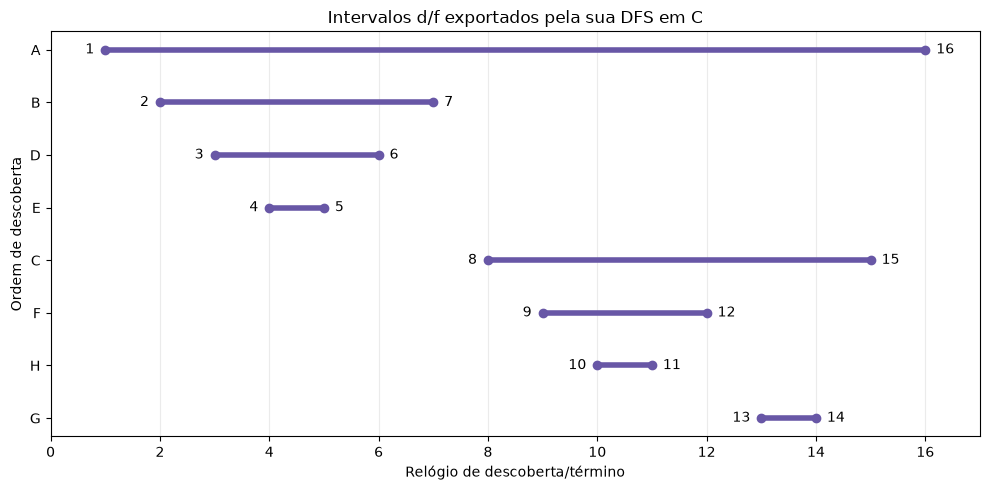

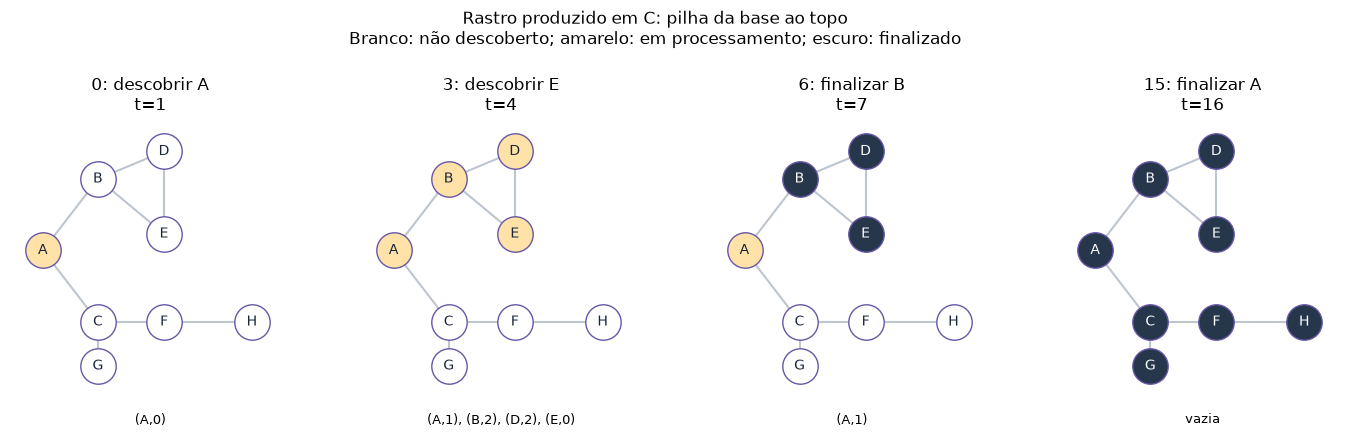

In [16]:
def exemplo_dos_slides():
    if not PRONTO: print('Visualizações aguardam suas implementações.');return None
    entrada=gravar_grafo('aula.in',8,ARESTAS_AULA,0)
    t,m,c=rodar(entrada,'iter','aula')
    print(t.assign(nome=t.vertice.map(lambda x:chr(65+x))).to_string(index=False))
    print('Métricas calculadas em C:',m)
    print('Caminho de A até H (calculado em C):',c[c.destino==7].caminho.iloc[0])
    fig,ax=plt.subplots(figsize=(10,5))
    for _,linha in t.sort_values('descoberta').iterrows():
        y=int(linha.ordem_descoberta)
        ax.plot([linha.descoberta,linha.termino],[y,y],marker='o',linewidth=4,color='#6857a6')
        ax.text(linha.descoberta-.2,y,str(int(linha.descoberta)),ha='right',va='center')
        ax.text(linha.termino+.2,y,str(int(linha.termino)),ha='left',va='center')
    ordem=t.sort_values('descoberta').vertice
    ax.set_yticks(range(8),[chr(65+v) for v in ordem]);ax.invert_yaxis()
    ax.set(xlabel='Relógio de descoberta/término',ylabel='Ordem de descoberta',title='Intervalos d/f exportados pela sua DFS em C')
    ax.set_xlim(0,17);ax.grid(axis='x',alpha=.25);fig.tight_layout();plt.show()
    visualizar_rastro('aula.rastro.csv',8,ARESTAS_AULA,indices=[0,3,6,15])
    return t,m,c

def visualizar_rastro(arquivo,n,arestas,indices=None):
    rastro=pd.read_csv(arquivo,keep_default_na=False)
    if rastro.empty: print('Rastro vazio: não houve descoberta.');return
    if indices is None:indices=list(range(min(4,len(rastro))))
    if n==8:
        pos={0:(-1,0),1:(-.5,.65),2:(-.5,-.65),3:(.1,.9),4:(.1,.15),5:(.1,-.65),6:(-.5,-1.05),7:(.9,-.65)}
    else:pos={u:(math.cos(2*math.pi*u/n),math.sin(2*math.pi*u/n)) for u in range(n)}
    fig,axs=plt.subplots(1,len(indices),figsize=(4.3*len(indices),5.2),squeeze=False)
    for ax,i in zip(axs[0],indices):
        linha=rastro.iloc[i];est=[int(x) for x in str(linha.estados).split(';')]
        for u,v in arestas:ax.plot([pos[u][0],pos[v][0]],[pos[u][1],pos[v][1]],color='#bdc5cf',zorder=1)
        for u in range(n):
            ax.scatter(*pos[u],s=650,c={0:'#ffffff',1:'#ffe2a8',2:'#26374c'}[est[u]],edgecolors='#6857a6',zorder=2)
            ax.text(*pos[u],chr(65+u) if n<=26 else str(u),color='white' if est[u]==2 else '#17243a',ha='center',va='center',zorder=3)
        quadros=[]
        for item in str(linha.pilha).split(';'):
            if item:
                u,j=map(int,item.split(':'));quadros.append(f'({chr(65+u) if n<=26 else u},{j})')
        import textwrap
        ax.text(.5,-.05,'\n'.join(textwrap.wrap(', '.join(quadros) or 'vazia',32)),transform=ax.transAxes,ha='center',va='top',fontsize=9)
        ax.set_title(f'{i}: {linha.evento} {chr(65+int(linha.vertice)) if n<=26 else linha.vertice}\nt={linha.tempo}')
        ax.set_xlim(-1.3,1.25);ax.set_ylim(-1.35,1.2);ax.set_aspect('equal');ax.axis('off')
    fig.suptitle('Rastro produzido em C: pilha da base ao topo\nBranco: não descoberto; amarelo: em processamento; escuro: finalizado')
    fig.subplots_adjust(top=.8,bottom=.2,wspace=.25);plt.show()

resultado_aula = exemplo_dos_slides()


**7.1 — Leitura do rastro**

- **Quando E é descoberto** (evento 3), a pilha é `(A,1), (B,2), (D,2), (E,0)`: as chamadas ativas são A, B, D e E, nessa ordem da base ao topo.
- **Depois que D termina** (evento 5), a pilha fica `(A,1), (B,2)`: B continua na posição 2 da sua lista (A, D, E), isto é, no vizinho E.
- **E não é chamado de novo** porque já está finalizado (estado 2). Só vértices não descobertos geram nova chamada; E apenas conta como uma entrada examinada. O ciclo B–D–E já tinha sido detectado antes, quando E viu B ainda em processamento e B não era seu pai.
- **O relógio não muda** ao examinar um vizinho já descoberto porque ele só anda nos eventos de descoberta e de término. Examinar um vizinho visto não é nenhum dos dois.


## 13. Exercício 7 — Experimento lista × matriz e recursão × iteração

A célula pronta gera cadeias e grafos esparsos conexos com 100, 200, 400 e 800 vértices. Cada rede é criada uma única vez por tamanho/família e fornecida às três versões.

Cada repetição mede **20 percursos no programa C**. A exportação ocorre depois do intervalo medido. Há aquecimento e cinco repetições; o gráfico usa a mediana dos tempos médios por percurso. O relógio é `clock()` da biblioteca C, que mede tempo de CPU e pode ter resolução insuficiente para casos pequenos. Valor zero não significa ausência de trabalho.

Construção do grafo, conversão para matriz, geração de dados, exportação, compilação e execução do Python ficam fora do tempo medido. A reinicialização dos vetores e a alocação/liberação da pilha explícita estão incluídas na função de percurso. Não há rastro no benchmark.

A exportação do rastro copia estados e percorre quadros/listas, acrescentando custo que não pertence ao núcleo Θ(V+E). Use-a apenas para exemplos pequenos. Ela não está incluída na memória máxima de chamadas/quadros apresentada na métrica.

**Não altere o apoio para implementar uma DFS pronta apenas para medir operações**: o experimento deve chamar as mesmas funções que você escreveu e testou.


familia modo   V    E  tempo_mediano_us  exames  max_pilha
 cadeia iter 100   99              5.30     198        100
 cadeia iter 200  199             10.55     398        200
 cadeia iter 400  399             14.90     798        400
 cadeia iter 800  799             29.85    1598        800
 cadeia  mat 100   99             23.45   10000        100
 cadeia  mat 200  199             58.70   40000        200
 cadeia  mat 400  399            194.95  160000        400
 cadeia  mat 800  799            832.00  640000        800
 cadeia  rec 100   99              4.00     198        100
 cadeia  rec 200  199              6.65     398        200
 cadeia  rec 400  399              9.55     798        400
 cadeia  rec 800  799             19.90    1598        800
esparso iter 100  200              6.45     400        100
esparso iter 200  400             15.70     800        200
esparso iter 400  800             27.50    1600        400
esparso iter 800 1600             57.30    3200        8

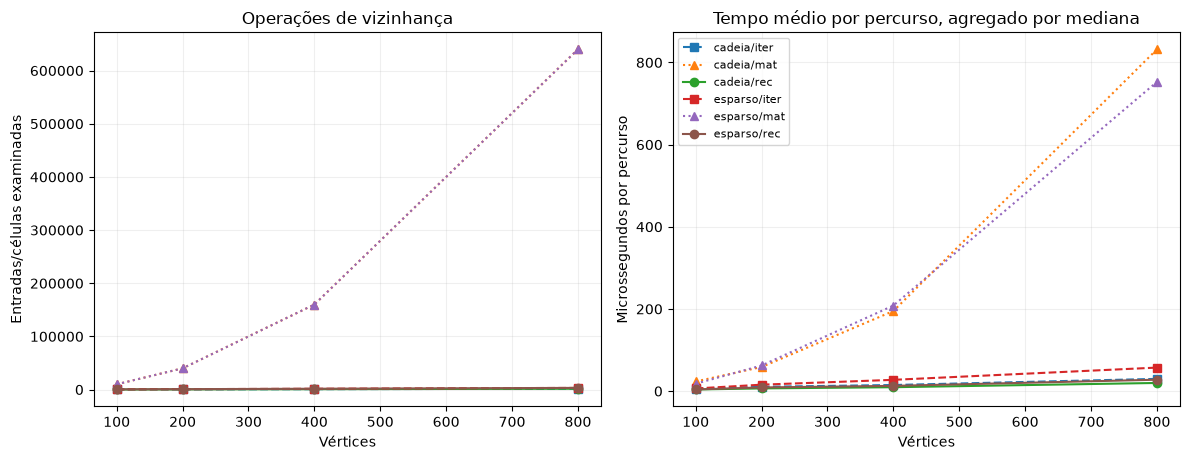

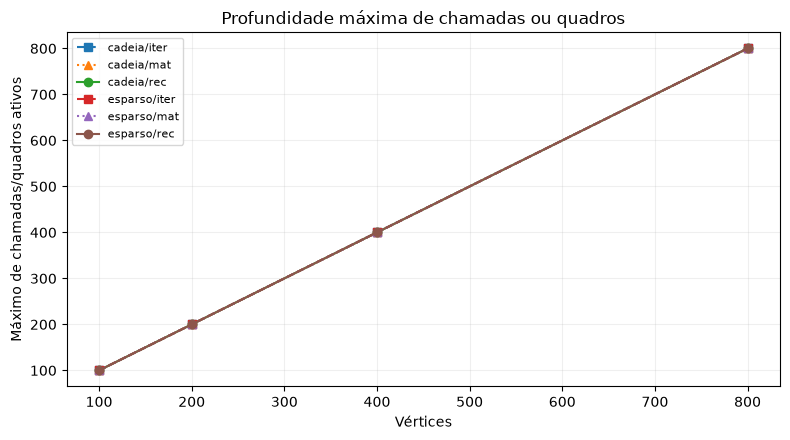

In [17]:
def experimento():
    if not PRONTO: print('Experimento aguarda suas implementações.');return None
    linhas=[];rng=random.Random(503)
    for familia in ['cadeia','esparso']:
        for n in [100,200,400,800]:
            es={(u,u+1) for u in range(n-1)}
            if familia=='esparso':
                while len(es)<2*n:
                    u,v=sorted(rng.sample(range(n),2));es.add((u,v))
            entrada=gravar_grafo('benchmark.in',n,sorted(es),0)
            for modo in ['rec','iter','mat']:
                rodar(entrada,modo,'aquecimento',2)
                for rep in range(5):
                    # 20 percursos dentro do C; sem exportação e sem rastro no intervalo medido.
                    _,m,_=rodar(entrada,modo,'bench',20)
                    m.update(familia=familia,repeticao=rep);linhas.append(m)
    dados=pd.DataFrame(linhas)
    dados.to_csv('benchmark_dfs.csv',index=False)
    resumo=dados.groupby(['familia','modo','V'],as_index=False).agg(
        E=('E','first'),tempo_mediano_us=('tempo_us','median'),
        exames=('exames','first'),max_pilha=('max_pilha','first'))
    print(resumo.to_string(index=False))
    fig,axs=plt.subplots(1,2,figsize=(12,4.7))
    for (familia,modo),grupo in resumo.groupby(['familia','modo']):
        estilo={'rec':'o-','iter':'s--','mat':'^:'}[modo]
        axs[0].plot(grupo.V,grupo.exames,estilo,label=f'{familia}/{modo}')
        axs[1].plot(grupo.V,grupo.tempo_mediano_us,estilo,label=f'{familia}/{modo}')
    axs[0].set(title='Operações de vizinhança',xlabel='Vértices',ylabel='Entradas/células examinadas')
    axs[1].set(title='Tempo médio por percurso, agregado por mediana',xlabel='Vértices',ylabel='Microssegundos por percurso')
    for ax in axs:ax.grid(alpha=.2)
    axs[1].legend(fontsize=8);fig.tight_layout();plt.show()
    fig,ax=plt.subplots(figsize=(8,4.5))
    for (familia,modo),grupo in resumo.groupby(['familia','modo']):
        ax.plot(grupo.V,grupo.max_pilha,{'rec':'o-','iter':'s--','mat':'^:'}[modo],label=f'{familia}/{modo}')
    ax.set(title='Profundidade máxima de chamadas ou quadros',xlabel='Vértices',ylabel='Máximo de chamadas/quadros ativos')
    ax.legend(fontsize=8);ax.grid(alpha=.2);fig.tight_layout();plt.show()
    return resumo

resumo_experimento = experimento()


### Análise do experimento

1. Compare a quantidade de exames com 2E e n². Por que a razão de crescimento difere?
2. Recursão e iteração com lista examinam o mesmo número de entradas. Isso exige que os tempos também sejam iguais?
3. Em uma cadeia, qual é a maior profundidade de chamadas/quadros? Ela se confunde com a memória do grafo?
4. Por que a comparação entre listas com vizinhos em outra ordem pode mudar a árvore sem alterar componentes ou existência de ciclo?
5. Quando uma matriz ainda pode ser conveniente, apesar da varredura de linhas completas?
6. Por que uma pilha apenas de vértices pode guardar candidatos repetidos e não permitir deduzir os mesmos tempos de término?


**8.1 — Interpretação experimental**

1. A lista examinou exatamente 2E entradas (cadeia com 800: 1.598; esparso com 800: 3.200) e a matriz, n² (640.000). Ao dobrar V, os exames da lista dobram (E cresce junto com V nessas redes), e os da matriz quadruplicam, porque cada vértice varre uma linha de tamanho n. O tempo seguiu isso: na matriz da cadeia, foi de 195 µs para 832 µs de 400 para 800 vértices.
2. Não. O trabalho de examinar vizinhos é o mesmo, mas a iterativa faz coisas a mais: aloca e libera a pilha, copia quadros e chama funções da pilha. Com 800 vértices, a recursiva levou cerca de 20 µs na cadeia e 28 µs no esparso, contra 30 µs e 57 µs da iterativa. Medidas tão pequenas também sofrem com a resolução do `clock()`.
3. Em uma cadeia, a profundidade máxima é igual a V (800 quadros para 800 vértices), porque a busca desce de uma ponta à outra sem voltar. Isso não é a memória do grafo: o grafo ocupa suas listas o tempo todo (V + 2E), enquanto a pilha é memória extra e temporária, que depende do formato da rede, e não do número de arestas.
4. A ordem dos vizinhos só escolhe qual vizinho não descoberto é visitado primeiro, o que muda pais e tempos. Mas quem consegue chegar em quem não depende da ordem, então as componentes são as mesmas. A existência de ciclo depende só de E > V − c, que também não muda. O teste 2 mostra isso: árvore diferente, mesmas componentes, ciclo e exames.
5. Quando o grafo é denso (quase todos ligados a todos), pois aí 2E já fica perto de n² e a lista perde a vantagem; quando o grafo é pequeno; ou quando é preciso responder rápido se existe a ligação u–v, consultando uma única célula.
6. Na pilha só de vértices, um vértice pode ser empilhado por vários vizinhos antes de ser visitado, gerando cópias repetidas. Além disso, ela não guarda em que ponto da lista cada vértice parou: ao retirar um vértice, ele sai de vez, e não há o momento de "voltar" para ele depois que todos os vizinhos terminaram. Sem esse retorno, não se sabe quando atribuir `f`, e os tempos de término não saem iguais aos da recursão.


## 14. Dois testes próprios e conclusão

Escreva em uma célula de código dois testes adicionais usando `gravar_grafo` e `rodar` para chamar suas funções em C. Sugestões: ciclo somente na segunda componente; inverter a ordem das arestas e observar a árvore; origem em um vértice isolado; executar duas vezes o mesmo resultado no C.

Explique o erro que cada teste procura detectar. Em seguida, escreva uma conclusão de 150–250 palavras: quando usaria recursão ou pilha explícita, como o código retoma a lista e por que DFS não é uma substituição geral de BFS para rotas mínimas. Mencione uma evidência de correção e duas medidas do experimento.


In [18]:
def teste_ciclo_segunda_componente():
    arestas = [(1, 2), (2, 3), (3, 1), (4, 5), (5, 6)]
    entrada = gravar_grafo('proprio1.in', 7, arestas, 0)
    t1, m1, c1 = rodar(entrada, 'rec', 'proprio1_uma', 1)
    t3, m3, c3 = rodar(entrada, 'rec', 'proprio1_tres', 3)
    ti, mi, _ = rodar(entrada, 'iter', 'proprio1_iter', 1)
    tm, mm, _ = rodar(entrada, 'mat', 'proprio1_mat', 1)

    assert m1['componentes'] == 3 and m1['ciclo'] == 1
    assert mi['ciclo'] == 1 and mm['ciclo'] == 1
    assert t1.componente.tolist() == [0, 1, 1, 1, 2, 2, 2]
    assert t1.loc[t1.vertice == 0, 'termino'].iloc[0] == 2
    assert c1.tamanho.tolist() == [1, 0, 0, 0, 0, 0, 0]
    pd.testing.assert_frame_equal(t1, t3)
    pd.testing.assert_frame_equal(t1, ti)
    print('Teste 1: ciclo achado só na 2a componente, origem isolada e reexecução sem resíduos.')
    print(t1.to_string(index=False))

def teste_ordem_invertida():
    entrada = gravar_grafo('proprio2a.in', 8, ARESTAS_AULA, 0)
    ta, ma, _ = rodar(entrada, 'iter', 'proprio2a', 1)
    entrada = gravar_grafo('proprio2b.in', 8, list(reversed(ARESTAS_AULA)), 0)
    tb, mb, cb = rodar(entrada, 'iter', 'proprio2b', 1)
    tr, mr, _ = rodar(entrada, 'rec', 'proprio2b_rec', 1)

    assert ta.pai.tolist() != tb.pai.tolist()
    assert (ma['componentes'], ma['ciclo'], ma['exames']) == (mb['componentes'], mb['ciclo'], mb['exames'])
    pd.testing.assert_frame_equal(tb, tr)
    nomes = lambda t: ','.join(chr(65 + v) for v in t.sort_values('descoberta').vertice)
    print('Teste 2: mesma rede com arestas invertidas.')
    print('  descoberta original:', nomes(ta), '| pais:', ta.pai.tolist())
    print('  descoberta invertida:', nomes(tb), '| pais:', tb.pai.tolist())
    print('  caminho A->H original: 0;2;5;7 | invertido:', cb[cb.destino == 7].caminho.iloc[0])
    print('  componentes, ciclo e exames iguais; recursiva == iterativa na ordem invertida.')

teste_ciclo_segunda_componente()
teste_ordem_invertida()

Teste 1: ciclo achado só na 2a componente, origem isolada e reexecução sem resíduos.
 vertice  estado  pai  descoberta  termino  componente  ordem_descoberta  ordem_termino
       0       2   -1           1        2           0                 0              0
       1       2   -1           3        8           1                 1              3
       2       2    1           4        7           1                 2              2
       3       2    2           5        6           1                 3              1
       4       2   -1           9       14           2                 4              6
       5       2    4          10       13           2                 5              5
       6       2    5          11       12           2                 6              4
Teste 2: mesma rede com arestas invertidas.
  descoberta original: A,B,D,E,C,F,H,G | pais: [-1, 0, 0, 1, 3, 2, 2, 5]
  descoberta invertida: A,C,G,F,H,B,E,D | pais: [-1, 0, 0, 4, 1, 2, 2, 5]
  caminho A->H origi

**9.1 — Testes e conclusão**

**Teste 1 — ciclo só na segunda componente, com origem isolada.** Rede com 7 vértices: o vértice 0 isolado (origem), um triângulo 1–2–3 e uma linha 4–5–6. Procura detectar: laço externo que para na primeira componente ou não começa uma árvore nova; ciclo verificado só na componente da origem; caminhos com lixo para vértices que a origem não alcança (devem ter tamanho 0). Também roda 3 vezes seguidas e compara com 1 execução, para pegar quem esquece de chamar `resultado_reinicia` (o relógio continuaria crescendo).

**Teste 2 — mesmas arestas da aula em ordem invertida.** Procura detectar: ordenação escondida das listas ou uma iterativa que visita os vizinhos em outra ordem. A árvore deve mudar (A,C,G,F,H,B,E,D em vez de A,B,D,E,C,F,H,G), mas componentes, ciclo e exames não, e a recursiva deve continuar idêntica à iterativa.

**Conclusão.** Eu usaria a recursão em grafos pequenos ou rasos, porque o código fica curto e segue direto o pseudocódigo. Para redes grandes ou muito profundas, como uma cadeia longa, prefiro a pilha explícita: a profundidade chega a V (800 quadros na cadeia de 800 vértices) e a pilha do sistema pode estourar, enquanto a pilha de quadros tem tamanho controlado. A retomada da lista funciona porque cada quadro guarda o vértice e o ponteiro `proximo` para o próximo vizinho ainda não examinado. Esse ponteiro avança antes de empilhar o filho, então, quando o filho termina, o pai continua exatamente de onde parou, sem recomeçar a lista. A DFS não substitui a BFS em rotas mínimas porque segue um ramo até o fim antes de voltar: no grafo da aula, o caminho de A até E na árvore é A–B–D–E (3 enlaces), embora A–B–E tenha só 2. Como evidência de correção, as versões recursiva e iterativa geraram tabelas idênticas nos 38 grafos de teste, inclusive com listas fora de ordem, e o caso da aula bateu com os tempos esperados. No experimento, com 800 vértices esparsos, a lista examinou 3.200 entradas (2E) contra 640.000 células (n²) da matriz, levando cerca de 28 µs contra 753 µs.


## Entrega e referências

Antes de entregar: identificação preenchida; nenhum `TODO` nas seis implementações; compilação e testes executados; gráficos produzidos pelo seu código C; dois testes próprios; respostas e conclusão. Não entregue somente saídas sem implementação. Registre uso de ferramentas externas conforme a política da disciplina.

Materiais-base:

- **Busca_em_Profundidade(1).pdf**, fornecido pelo professor: estados, exemplo e tempos na sequência detalhada; procedimento externo e versões recursiva/iterativa nas páginas finais 26–36 do PDF.
- **BFS_Busca_em_Largura_C_com_Python_ALUNOS.ipynb**, fornecido pelo professor: formato de atividade em C, lista ligada de adjacências, reconstrução por pais e experimentos com Python.
- Cormen et al. *Introduction to Algorithms*, 4ª ed., MIT Press, 2022, capítulo 20.
- Sedgewick e Wayne. *Algorithms*, 4ª ed., Addison-Wesley, 2011, seção 4.1.

Pseudocódigos adaptados ao contrato desta atividade. As referências de teste não são soluções de DFS em Python.
